In [ ]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src.black_scholes import bs_call
from src.mc_pricer import mc_european_call

# Параметры ATM опциона
S0, K, T, r, sigma = 100, 100, 1.0, 0.05, 0.2
bs_price = bs_call(S0, K, T, r, sigma)
print(f"Аналитическая цена (Black-Scholes): {bs_price:.4f}")


Аналитическая цена (Black-Scholes): 10.4506


In [5]:
N_values = [10**3, 10**4, 10**5, 10**6]
mc_prices = []
se_values = []
errors = []
for n in N_values:
    price, se = mc_european_call(S0, K, T, r, sigma, n_paths=n)
    mc_prices.append(price)
    se_values.append(se)
    errors.append(abs(price - bs_price))
    print(f"N = {n:>8}: MC price = {price:.4f}, Error = {abs(price - bs_price):.4f}, SE = {se:.4f}")

N =     1000: MC price = 9.9120, Error = 0.5386, SE = 0.4483
N =    10000: MC price = 10.3452, Error = 0.1054, SE = 0.1477
N =   100000: MC price = 10.4205, Error = 0.0300, SE = 0.0468
N =  1000000: MC price = 10.4532, Error = 0.0026, SE = 0.0147


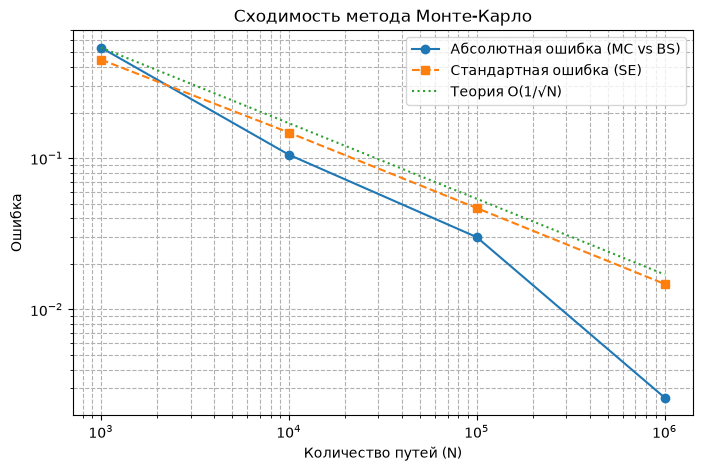

In [6]:
plt.figure(figsize=(8, 5))
plt.loglog(N_values, errors, marker='o', label='Абсолютная ошибка (MC vs BS)')
plt.loglog(N_values, se_values, marker='s', linestyle='--', label='Стандартная ошибка (SE)')

# Добавим теоретическую линию O(1/sqrt(N)) для сравнения
theoretical = [errors[0] * np.sqrt(N_values[0] / n) for n in N_values]
plt.loglog(N_values, theoretical, linestyle=':', label='Теория O(1/√N)')

plt.xlabel('Количество путей (N)')
plt.ylabel('Ошибка')
plt.title('Сходимость метода Монте-Карло')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

In [4]:
from src.variance_reduction import mc_call_antithetic, mc_call_control_variate

N_test = 100_000

price_plain, se_plain = mc_european_call(S0, K, T, r, sigma, n_paths=N_test)
price_anti, se_anti = mc_call_antithetic(S0, K, T, r, sigma, n_paths=N_test)
price_cv, se_cv = mc_call_control_variate(S0, K, T, r, sigma, n_paths=N_test)

print(f"Обычный MC:       Цена = {price_plain:.4f}, SE = {se_plain:.5f}")
print(f"Antithetic:       Цена = {price_anti:.4f},  SE = {se_anti:.5f} (Ускорение: {se_plain/se_anti:.1f}x)")
print(f"Control Variate:  Цена = {price_cv:.4f},  SE = {se_cv:.5f} (Ускорение: {se_plain/se_cv:.1f}x)")

Обычный MC:       Цена = 10.4205, SE = 0.04677
Antithetic:       Цена = 10.4673,  SE = 0.03308 (Ускорение: 1.4x)
Control Variate:  Цена = 10.4668,  SE = 0.01788 (Ускорение: 2.6x)
